# Microproyecto 03
## Clasificación Multi-Clase de Artículos de Noticias de la BBC usando Transformers

**Materia:** Técnicas de Deep Learning  
**Programa:** Maestría en IA  
**Estudiantes:** Sergio Pardo, Jefferson Moreno, John Pino  
**Fecha:** Mayo 2026  

---

## 1. Contexto del problema

Los artículos de noticias contienen información textual que puede asociarse con categorías temáticas como deportes, negocios, política, tecnología y entretenimiento. En este microproyecto se abordará una tarea de **clasificación multi-clase** sobre artículos de la BBC, donde cada texto debe asignarse a una única categoría.

Los modelos basados en transformers, como `BERT` o `RoBERTa`, son adecuados para este problema porque capturan relaciones contextuales entre palabras sin depender de procesamiento secuencial recurrente. Esto permite construir representaciones textuales más ricas para clasificar documentos completos.

Dataset propuesto en el enunciado:

- Kaggle: `jacopoferretti/bbc-articles-dataset`

## 2. Objetivo

Desarrollar un modelo de clasificación multi-clase basado en transformers que identifique la categoría temática de artículos de noticias de la BBC.

Para cumplir este objetivo se construirá un pipeline que incluya carga del dataset, exploración inicial, limpieza ligera del texto, codificación de etiquetas, tokenización con un modelo preentrenado, ajuste fino de un transformer para clasificación de secuencias y evaluación mediante accuracy, precision, recall, F1-score y análisis por categoría.

## 3. Configuración inicial

Se importan las librerías principales y se define la configuración base del experimento. Como el microproyecto se desarrollará con `PyTorch`, desde el inicio se deja configurado el dispositivo de ejecución y las semillas de reproducibilidad.

Esta sección se irá actualizando conforme avance el desarrollo del pipeline.

In [1]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from torch.utils.data import DataLoader, Dataset
from transformers import AutoTokenizer, BertForSequenceClassification
from tqdm.auto import tqdm

RANDOM_SEED = 42
BASE_DIR = Path.cwd()
DATASET_DIR = BASE_DIR / "dataset"
MODEL_NAME = "bert-base-uncased"
MAX_LENGTH = 256
BATCH_SIZE = 16
NUM_EPOCHS = 5
LEARNING_RATE = 2e-5

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

pd.set_option("display.max_colwidth", 120)

print(f"Directorio base: {BASE_DIR}")
print(f"Dispositivo PyTorch: {device}")

Directorio base: /Users/johnpino/Maestria/TDL/Microproyecto 03
Dispositivo PyTorch: cpu


## 4. Dataset

El dataset se descargará desde Kaggle mediante `kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")` y se guardará en la carpeta local `dataset/` del proyecto. Esta carpeta está excluida del control de versiones mediante `.gitignore`, por lo que el notebook mantiene una ruta estable sin subir los datos al repositorio.

Aspectos esperados:

- Ruta local del dataset dentro del proyecto.
- Archivo usado como fuente principal.
- Columnas disponibles.
- Identificación de la columna de artículo y de la columna de categoría.

In [2]:
import kagglehub

DATASET_DIR.mkdir(exist_ok=True)
dataset_path = Path(
    kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset", output_dir=DATASET_DIR)
)

dataset_file = dataset_path / "archive" / "bbc_text_cls.csv"
if not dataset_file.exists():
    raise FileNotFoundError(f"No se encontro el archivo esperado: {dataset_file}")

df_raw = pd.read_csv(dataset_file)

print(f"Ruta del dataset: {dataset_path}")
print(f"Archivo cargado: {dataset_file.name}")
print(f"Filas: {df_raw.shape[0]:,} | Columnas: {df_raw.shape[1]}")
display(df_raw.head())

Ruta del dataset: /Users/johnpino/Maestria/TDL/Microproyecto 03/dataset
Archivo cargado: bbc_text_cls.csv
Filas: 2,225 | Columnas: 2


,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) fo...,business
1,Dollar gains on Greenspan speech\n\nThe dollar has hit its highest level against the euro in almost three months aft...,business
2,Yukos unit buyer faces loan claim\n\nThe owners of embattled Russian oil giant Yukos are to ask the buyer of its for...,business
3,High fuel prices hit BA's profits\n\nBritish Airways has blamed high fuel prices for a 40% drop in profits.\n\nRepor...,business
4,Pernod takeover talk lifts Domecq\n\nShares in UK drinks and food firm Allied Domecq have risen on speculation that ...,business


## 5. Exploración inicial del dataset

En esta sección se realiza una exploración rápida del dataset para validar estructura, volumen, clases, balance de categorías, textos vacíos o duplicados y longitud de los artículos.

El archivo seleccionado contiene dos columnas principales: `text`, con el artículo completo, y `labels`, con la categoría temática.

### 5.1 Revisión de estructura y valores faltantes

In [3]:
TEXT_COLUMN = "text"
LABEL_COLUMN = "labels"
df = df_raw[[TEXT_COLUMN, LABEL_COLUMN]].copy()

print(f"Dimension del dataset: {df.shape}")
display(df.head())

df.isna().sum().to_frame("valores_faltantes")

Dimension del dataset: (2225, 2)


,text,labels
0,Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) fo...,business
1,Dollar gains on Greenspan speech\n\nThe dollar has hit its highest level against the euro in almost three months aft...,business
2,Yukos unit buyer faces loan claim\n\nThe owners of embattled Russian oil giant Yukos are to ask the buyer of its for...,business
3,High fuel prices hit BA's profits\n\nBritish Airways has blamed high fuel prices for a 40% drop in profits.\n\nRepor...,business
4,Pernod takeover talk lifts Domecq\n\nShares in UK drinks and food firm Allied Domecq have risen on speculation that ...,business


,valores_faltantes
text,0
labels,0


### 5.2 Revisión del balance de categorías

,cantidad,porcentaje
labels,,
business,510,22.92
entertainment,386,17.35
politics,417,18.74
sport,511,22.97
tech,401,18.02


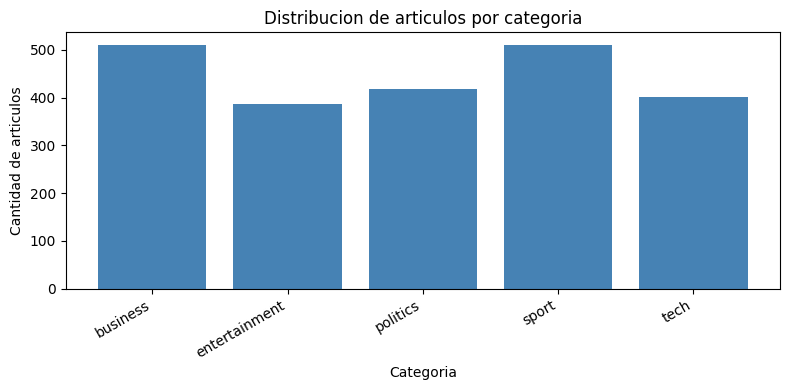

In [4]:
class_counts = df[LABEL_COLUMN].value_counts().sort_index()
class_distribution = class_counts.to_frame("cantidad")
class_distribution["porcentaje"] = (class_distribution["cantidad"] / len(df) * 100).round(2)
display(class_distribution)

plt.figure(figsize=(8, 4))
plt.bar(class_counts.index, class_counts.values, color="steelblue")
plt.title("Distribucion de articulos por categoria")
plt.xlabel("Categoria")
plt.ylabel("Cantidad de articulos")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 5.3 Revisión de duplicados y textos vacíos

In [5]:
text_as_string = df[TEXT_COLUMN].fillna("").astype(str)

duplicate_text_count = df.duplicated(subset=[TEXT_COLUMN]).sum()
empty_text_count = text_as_string.str.strip().eq("").sum()
duplicate_rows_count = df.duplicated().sum()

print(f"Textos duplicados exactos: {duplicate_text_count}")
print(f"Filas completas duplicadas: {duplicate_rows_count}")
print(f"Textos vacios: {empty_text_count}")

if duplicate_text_count > 0:
    display(df[df.duplicated(subset=[TEXT_COLUMN], keep=False)].sort_values(TEXT_COLUMN).head(10))

Textos duplicados exactos: 98
Filas completas duplicadas: 98
Textos vacios: 0


,text,labels
1989,'Brainwave' cap controls computer\n\nA team of US researchers has shown that controlling devices with the brain is a...,tech
1988,'Brainwave' cap controls computer\n\nA team of US researchers has shown that controlling devices with the brain is a...,tech
954,"'Debate needed' on donations cap\n\nA cap on donations to political parties should not be introduced yet, the electi...",politics
1193,"'Debate needed' on donations cap\n\nA cap on donations to political parties should not be introduced yet, the electi...",politics
1003,"'Super union' merger plan touted\n\nTwo of Britain's big trade unions could merge to form a ""super union"" of two mil...",politics
1186,"'Super union' merger plan touted\n\nTwo of Britain's big trade unions could merge to form a ""super union"" of two mil...",politics
1994,'Ultimate game' award for Doom 3\n\nSci-fi shooter Doom 3 has blasted away the competition at a major games ceremony...,tech
1949,'Ultimate game' award for Doom 3\n\nSci-fi shooter Doom 3 has blasted away the competition at a major games ceremony...,tech
1992,"2D Metal Slug offers retro fun\n\nLike some drill sergeant from the past, Metal Slug 3 is a wake-up call to today's ...",tech
2056,"2D Metal Slug offers retro fun\n\nLike some drill sergeant from the past, Metal Slug 3 is a wake-up call to today's ...",tech


### 5.4 Análisis de longitud de los artículos

Este análisis servirá para escoger una longitud máxima de tokenización que controle el costo computacional sin truncar excesivamente los textos.

,word_count,char_count
count,2225.00,2225.00
mean,384.04,2264.16
std,238.17,1364.10
min,89.00,502.00
50%,332.00,1966.00
75%,471.00,2803.00
90%,616.60,3629.20
95%,729.00,4287.80
99%,1002.52,5805.00
max,4432.00,25484.00


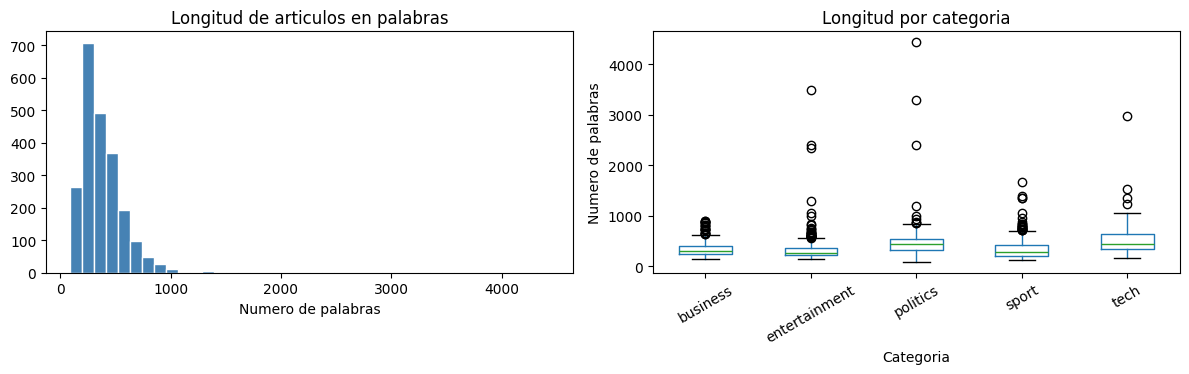

In [6]:
df["word_count"] = df[TEXT_COLUMN].fillna("").astype(str).str.split().str.len()
df["char_count"] = df[TEXT_COLUMN].fillna("").astype(str).str.len()

length_summary = df[["word_count", "char_count"]].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
).round(2)
display(length_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["word_count"], bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Longitud de articulos en palabras")
axes[0].set_xlabel("Numero de palabras")

df.boxplot(column="word_count", by=LABEL_COLUMN, ax=axes[1], grid=False)
axes[1].set_title("Longitud por categoria")
axes[1].set_xlabel("Categoria")
axes[1].set_ylabel("Numero de palabras")
axes[1].tick_params(axis="x", rotation=30)

fig.suptitle("")
plt.tight_layout()
plt.show()

### 5.5 Conclusiones del EDA

El dataset contiene `2225` artículos y dos columnas principales: `text`, con el contenido textual completo, y `labels`, con la categoría del artículo. No se observan valores faltantes ni textos vacíos, por lo que no es necesario aplicar imputaciones o eliminar registros por falta de información.

Las categorías disponibles son `business`, `entertainment`, `politics`, `sport` y `tech`. La distribución es relativamente balanceada: las clases con mayor número de ejemplos son `sport` con `511` artículos (`22.97%`) y `business` con `510` (`22.92%`), mientras que la clase con menor representación es `entertainment` con `386` artículos (`17.35%`). Esta diferencia no parece suficientemente fuerte como para requerir técnicas de rebalanceo en esta etapa, aunque se mantendrá una división estratificada en entrenamiento, validación y prueba.

Se encontraron `98` textos duplicados exactos, que también corresponden a `98` filas completas duplicadas. Estos registros deben eliminarse en el preprocesamiento para evitar fuga de información entre particiones y para que el modelo no evalúe ejemplos que ya vio durante entrenamiento.

En cuanto a longitud, los artículos tienen una mediana de `332` palabras y un promedio de `384.04` palabras. El percentil 75 es de `471` palabras, el percentil 95 es de `729` y el máximo llega a `4432` palabras. Esto indica que la mayoría de textos son de longitud moderada, pero existen artículos largos que probablemente serán truncados por el tokenizer del transformer. Por esta razón, la selección de `MAX_LENGTH` en la siguiente etapa debe balancear cobertura de información y costo computacional.

## 6. Preprocesamiento y preparación del pipeline

En esta sección se prepara el dataset para que pueda ser utilizado por un modelo transformer en `PyTorch`. El proceso incluye una limpieza mínima del texto, la eliminación de registros duplicados, la codificación numérica de las categorías y la división estratificada en conjuntos de entrenamiento, validación y prueba. La limpieza se aplica antes de la partición porque no aprende estadísticas del dataset; solo normaliza espacios y permite eliminar duplicados antes de separar los conjuntos. Finalmente, los artículos se transforman al formato esperado por BERT usando el tokenizer asociado a `bert-base-uncased`, incluyendo truncamiento, padding y la construcción de objetos `Dataset` y `DataLoader`.

### 6.1 Limpieza del texto

In [7]:
def clean_text(text):
    return " ".join(str(text).split())


df_clean = df.copy()
df_clean[TEXT_COLUMN] = df_clean[TEXT_COLUMN].apply(clean_text)
df_clean = df_clean.drop_duplicates(subset=[TEXT_COLUMN]).reset_index(drop=True)

print(f"Registros iniciales: {len(df):,}")
print(f"Registros despues de limpieza: {len(df_clean):,}")
print(f"Registros eliminados: {len(df) - len(df_clean):,}")
display(df_clean.head())

Registros iniciales: 2,225
Registros despues de limpieza: 2,125
Registros eliminados: 100


,text,labels,word_count,char_count
0,Ad sales boost Time Warner profit Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for t...,business,421,2558
1,Dollar gains on Greenspan speech The dollar has hit its highest level against the euro in almost three months after ...,business,384,2251
2,Yukos unit buyer faces loan claim The owners of embattled Russian oil giant Yukos are to ask the buyer of its former...,business,264,1550
3,High fuel prices hit BA's profits British Airways has blamed high fuel prices for a 40% drop in profits. Reporting i...,business,406,2400
4,Pernod takeover talk lifts Domecq Shares in UK drinks and food firm Allied Domecq have risen on speculation that it ...,business,265,1568


Al normalizar espacios y saltos de línea antes de eliminar duplicados, aparecen `2` duplicados más que fueron removidos.

### 6.2 Codificación de etiquetas

In [8]:
label_encoder = LabelEncoder()
df_clean["label_id"] = label_encoder.fit_transform(df_clean[LABEL_COLUMN])

id2label = {idx: label for idx, label in enumerate(label_encoder.classes_)}
label2id = {label: idx for idx, label in id2label.items()}
num_labels = len(label_encoder.classes_)

print(f"Numero de clases: {num_labels}")
display(pd.DataFrame({"label_id": id2label.keys(), "label": id2label.values()}))

Numero de clases: 5


,label_id,label
0,0,business
1,1,entertainment
2,2,politics
3,3,sport
4,4,tech


### 6.3 División en entrenamiento, validación y prueba

La partición debe ser estratificada para conservar la proporción de categorías en cada conjunto.

In [9]:
train_df, temp_df = train_test_split(
    df_clean,
    test_size=0.2,
    stratify=df_clean["label_id"],
    random_state=RANDOM_SEED,
)

val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df["label_id"],
    random_state=RANDOM_SEED,
)

print(f"Train: {train_df.shape}")
print(f"Validation: {val_df.shape}")
print(f"Test: {test_df.shape}")

Train: (1700, 5)
Validation: (212, 5)
Test: (213, 5)


### 6.4 Tokenización con el tokenizer preentrenado

In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

sample_tokens = tokenizer(
    train_df[TEXT_COLUMN].head(2).tolist(),
    padding="max_length",
    truncation=True,
    max_length=MAX_LENGTH,
    return_tensors="pt",
)

print(f"Modelo tokenizer: {MODEL_NAME}")
print(f"input_ids: {sample_tokens['input_ids'].shape}")
# La attention_mask marca con 1 los tokens reales y con 0 los tokens de padding que el modelo debe ignorar.
print(f"attention_mask: {sample_tokens['attention_mask'].shape}")

Modelo tokenizer: bert-base-uncased
input_ids: torch.Size([2, 256])
attention_mask: torch.Size([2, 256])


### 6.5 Construcción de datasets y dataloaders

In [11]:
class BBCNewsDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length):
        self.texts = dataframe[TEXT_COLUMN].tolist()
        self.labels = dataframe["label_id"].tolist()
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoded = self.tokenizer(
            self.texts[idx],
            padding="max_length",
            truncation=True,
            max_length=self.max_length,
            return_tensors="pt",
        )

        return {
            "input_ids": encoded["input_ids"].squeeze(0),
            "attention_mask": encoded["attention_mask"].squeeze(0),
            "labels": torch.tensor(self.labels[idx], dtype=torch.long),
        }


train_dataset = BBCNewsDataset(train_df, tokenizer, MAX_LENGTH)
val_dataset = BBCNewsDataset(val_df, tokenizer, MAX_LENGTH)
test_dataset = BBCNewsDataset(test_df, tokenizer, MAX_LENGTH)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE)

batch = next(iter(train_loader))
print(f"Batches de entrenamiento: {len(train_loader)}")
print(f"input_ids: {batch['input_ids'].shape}")
print(f"attention_mask: {batch['attention_mask'].shape}")
print(f"labels: {batch['labels'].shape}")

Batches de entrenamiento: 107
input_ids: torch.Size([16, 256])
attention_mask: torch.Size([16, 256])
labels: torch.Size([16])


## 7. Diseño de la arquitectura transformer

Para la arquitectura se utiliza `bert-base-uncased`, un modelo BERT preentrenado en inglés, y se adapta mediante `BertForSequenceClassification`. Esta clase conserva el encoder de BERT y agrega una cabeza de clasificación al final, con `num_labels` salidas, una por cada categoría del dataset. Durante entrenamiento, el modelo recibe las etiquetas enteras y calcula internamente la pérdida de entropía cruzada para clasificación multi-clase. En inferencia, los logits de salida pueden convertirse a probabilidades mediante `softmax`, y la clase predicha corresponde al logit con mayor valor.

In [12]:
model = BertForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=num_labels,
    id2label=id2label,
    label2id=label2id,
)

model.to(device)

print(f"Modelo base: {MODEL_NAME}")
print(f"Numero de clases: {model.config.num_labels}")
print(f"Dispositivo: {device}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Modelo base: bert-base-uncased
Numero de clases: 5
Dispositivo: cpu


## 8. Configuración del entrenamiento

En esta sección se definen los elementos necesarios para entrenar el modelo: número de épocas, tasa de aprendizaje, optimizador y ruta para guardar el mejor checkpoint. Se utiliza `AdamW`, una opción común para ajuste fino de transformers. Se entrena durante `5` épocas para observar el comportamiento del modelo.

In [13]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
BEST_MODEL_PATH = BASE_DIR / "mejor_modelo_bert.pt"

print("Configuracion de entrenamiento")
print(f"Epocas: {NUM_EPOCHS}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"Optimizador: {optimizer.__class__.__name__}")
print(f"Checkpoint: {BEST_MODEL_PATH.name}")

Configuracion de entrenamiento
Epocas: 5
Batch size: 16
Learning rate: 2e-05
Optimizador: AdamW
Checkpoint: mejor_modelo_bert.pt


## 9. Entrenamiento del modelo

En esta sección se ejecuta el ajuste fino de BERT sobre los artículos de la BBC. En cada época se calcula la pérdida y la exactitud en entrenamiento y validación. El modelo con menor pérdida de validación se guarda como checkpoint para usarlo después en la evaluación sobre el conjunto de prueba.

In [14]:
def train_one_epoch(model, dataloader, optimizer, device):
    model.train()
    total_loss = 0
    correct_predictions = 0
    total_examples = 0

    for batch in tqdm(dataloader, desc="Train", leave=False):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["labels"].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        logits = outputs.logits

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        total_loss += loss.item() * batch_size
        correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
        total_examples += batch_size

    return total_loss / total_examples, correct_predictions / total_examples


def evaluate_one_epoch(model, dataloader, device):
    model.eval()
    total_loss = 0
    correct_predictions = 0
    total_examples = 0

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Validation", leave=False):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            logits = outputs.logits

            batch_size = labels.size(0)
            total_loss += loss.item() * batch_size
            correct_predictions += (logits.argmax(dim=1) == labels).sum().item()
            total_examples += batch_size

    return total_loss / total_examples, correct_predictions / total_examples

In [15]:
history = []
best_val_loss = float("inf")

for epoch in range(NUM_EPOCHS):
    print(f"Epoca {epoch + 1}/{NUM_EPOCHS}")

    train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, device)
    val_loss, val_accuracy = evaluate_one_epoch(model, val_loader, device)

    history.append(
        {
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy,
        }
    )

    print(f"Train loss: {train_loss:.4f} | Train accuracy: {train_accuracy:.4f}")
    print(f"Val loss: {val_loss:.4f} | Val accuracy: {val_accuracy:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print("Checkpoint actualizado")

history_df = pd.DataFrame(history)
history_df

Epoca 1/5


Train:   0%|          | 0/107 [00:00<?, ?it/s]

Validation:   0%|          | 0/14 [00:00<?, ?it/s]

Train loss: 0.5879 | Train accuracy: 0.8735
Val loss: 0.1525 | Val accuracy: 0.9717
Checkpoint actualizado
Epoca 2/5


Train:   0%|          | 0/107 [00:00<?, ?it/s]

...

Train loss: 0.0216 | Train accuracy: 0.9971
Val loss: 0.1105 | Val accuracy: 0.9764
Epoca 5/5


Train:   0%|          | 0/107 [00:00<?, ?it/s]

Validation:   0%|          | 0/14 [00:00<?, ?it/s]

Train loss: 0.0182 | Train accuracy: 0.9959
Val loss: 0.2790 | Val accuracy: 0.9434


,epoch,train_loss,train_accuracy,val_loss,val_accuracy
0,1,0.587915,0.873529,0.152510,0.971698
1,2,0.088463,0.983529,0.072100,0.976415
2,3,0.031351,0.995294,0.079391,0.981132
3,4,0.021631,0.997059,0.110525,0.976415
4,5,0.018223,0.995882,0.278996,0.943396


### 9.1 Curvas de entrenamiento

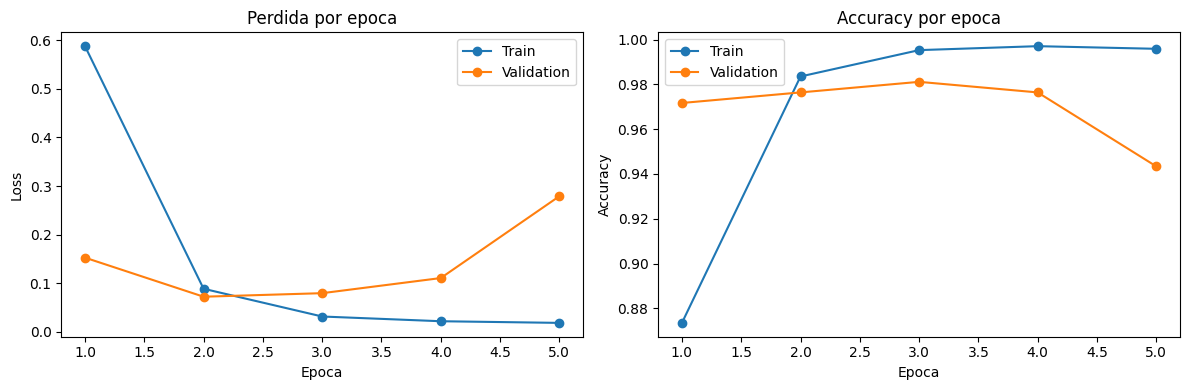

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train")
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation")
axes[0].set_title("Perdida por epoca")
axes[0].set_xlabel("Epoca")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history_df["epoch"], history_df["train_accuracy"], marker="o", label="Train")
axes[1].plot(history_df["epoch"], history_df["val_accuracy"], marker="o", label="Validation")
axes[1].set_title("Accuracy por epoca")
axes[1].set_xlabel("Epoca")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()

### 9.2 Conclusiones preliminares del entrenamiento

Durante las primeras épocas el modelo mejora de forma clara, con reducción de la pérdida y aumento de la exactitud. Sin embargo, después de la época `3` la pérdida de validación empieza a subir mientras la pérdida de entrenamiento continúa bajando hasta valores muy pequeños. Además, la accuracy de entrenamiento se mantiene casi perfecta, pero la accuracy de validación cae en la última época. Este comportamiento confirma un proceso de sobreajuste, por lo que resulta adecuado conservar el checkpoint con menor pérdida de validación en lugar de usar el último estado del modelo.

## 10. Evaluación en el conjunto de prueba

La evaluación debe realizarse con el mejor checkpoint guardado durante entrenamiento. Para inferencia multi-clase se deben convertir los logits a probabilidades con `softmax` y seleccionar la clase con mayor probabilidad.

In [17]:
def predict(model, dataloader, device):
    model.eval()
    true_labels = []
    predicted_labels = []
    predicted_probabilities = []

    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Test", leave=False):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["labels"].to(device)

            outputs = model(input_ids=input_ids, attention_mask=attention_mask)
            probabilities = torch.softmax(outputs.logits, dim=1)
            predictions = probabilities.argmax(dim=1)

            true_labels.extend(labels.cpu().numpy())
            predicted_labels.extend(predictions.cpu().numpy())
            predicted_probabilities.extend(probabilities.cpu().numpy())

    return np.array(true_labels), np.array(predicted_labels), np.array(predicted_probabilities)


model.load_state_dict(torch.load(BEST_MODEL_PATH, map_location=device))
model.to(device)

y_true, y_pred, y_prob = predict(model, test_loader, device)
test_accuracy = accuracy_score(y_true, y_pred)

print(f"Accuracy en test: {test_accuracy:.4f}")

Test:   0%|          | 0/14 [00:00<?, ?it/s]

Accuracy en test: 0.9624


### 10.1 Reporte de métricas por categoría

In [18]:
report = classification_report(
    y_true,
    y_pred,
    target_names=label_encoder.classes_,
    digits=4,
    output_dict=True,
)

report_df = pd.DataFrame(report).transpose()
display(report_df)

print(classification_report(y_true, y_pred, target_names=label_encoder.classes_, digits=4))

,precision,recall,f1-score,support
business,0.940000,0.940000,0.940000,50.000000
entertainment,0.948718,1.000000,0.973684,37.000000
politics,0.952381,0.975610,0.963855,41.000000
sport,1.000000,1.000000,1.000000,51.000000
tech,0.967742,0.882353,0.923077,34.000000
accuracy,0.962441,0.962441,0.962441,0.962441
macro avg,0.961768,0.959593,0.960123,213.000000
weighted avg,0.962692,0.962441,0.962108,213.000000


               precision    recall  f1-score   support

     business     0.9400    0.9400    0.9400        50
entertainment     0.9487    1.0000    0.9737        37
     politics     0.9524    0.9756    0.9639        41
        sport     1.0000    1.0000    1.0000        51
         tech     0.9677    0.8824    0.9231        34

     accuracy                         0.9624       213
    macro avg     0.9618    0.9596    0.9601       213
 weighted avg     0.9627    0.9624    0.9621       213



### 10.2 Matriz de confusión

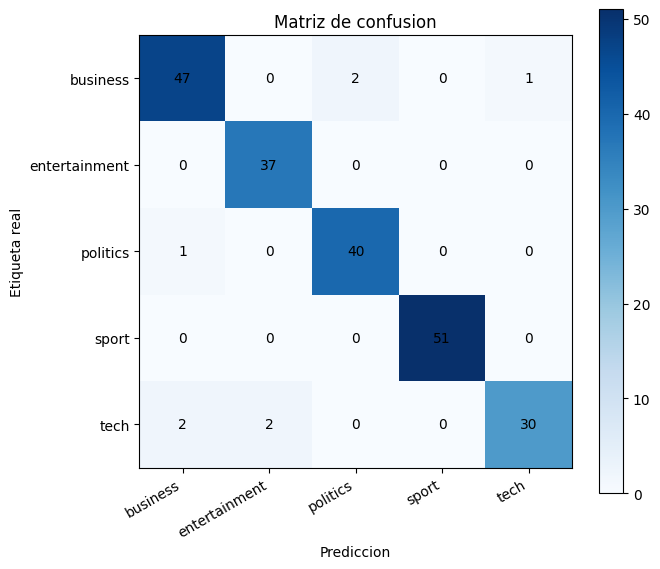

In [19]:
cm = confusion_matrix(y_true, y_pred)
class_names = label_encoder.classes_

fig, ax = plt.subplots(figsize=(7, 6))
image = ax.imshow(cm, cmap="Blues")
fig.colorbar(image, ax=ax)

ax.set_xticks(range(len(class_names)))
ax.set_yticks(range(len(class_names)))
ax.set_xticklabels(class_names, rotation=30, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("Prediccion")
ax.set_ylabel("Etiqueta real")
ax.set_title("Matriz de confusion")

for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(col, row, cm[row, col], ha="center", va="center", color="black")

plt.tight_layout()
plt.show()

### 10.3 Análisis de mejores y peores categorías

El modelo obtiene un buen desempeño general en el conjunto de prueba, con una accuracy de `0.9624` y un macro F1-score de `0.9601`. La categoría con mejor resultado es `sport`, con `precision`, `recall` y `f1-score` iguales a `1.0`, lo que indica que el modelo logra separarla muy bien del resto de clases.

La categoría con desempeño más bajo es `tech`, con un `recall` de `0.8824` y un `f1-score` de `0.9231`. Esto sugiere que algunos artículos reales de tecnología fueron clasificados como otra categoría. Aun así, el desempeño sigue siendo alto y la matriz de confusión muestra una concentración clara de aciertos en la diagonal principal.

## 11. Pruebas cualitativas con artículos externos o ejemplos manuales

Esta sección permite revisar de forma cualitativa si el modelo produce predicciones razonables ante textos nuevos. Estas pruebas no reemplazan la evaluación cuantitativa, pero ayudan a observar el comportamiento del modelo con ejemplos simples de cada categoría.

In [20]:
def predict_text(text):
    model.eval()
    encoded = tokenizer(
        clean_text(text),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt",
    )

    input_ids = encoded["input_ids"].to(device)
    attention_mask = encoded["attention_mask"].to(device)

    with torch.no_grad():
        outputs = model(input_ids=input_ids, attention_mask=attention_mask)
        probabilities = torch.softmax(outputs.logits, dim=1).squeeze(0)
        predicted_id = probabilities.argmax().item()

    return {
        "predicted_label": id2label[predicted_id],
        "confidence": probabilities[predicted_id].item(),
    }


examples = [
    "The company reported higher quarterly profits after strong sales in international markets.",
    "The striker danced through the defense and turned the stadium into a roaring sea.", # Evaluar figuras literarias.
    "What a surprise: politicians promised transparency again right before the election.", # Evaluar sarcasmo.
    "The new smartphone includes a faster processor and improved artificial intelligence features.",
    "The film painted heartbreak in neon colors, and the audience left carrying the final scene like a song.",
]

manual_results = []
for example in examples:
    prediction = predict_text(example)
    manual_results.append(
        {
            "text": example,
            "predicted_label": prediction["predicted_label"],
            "confidence": round(prediction["confidence"], 4),
        }
    )

display(pd.DataFrame(manual_results))

,text,predicted_label,confidence
0,The company reported higher quarterly profits after strong sales in international markets.,business,0.9661
1,The striker danced through the defense and turned the stadium into a roaring sea.,sport,0.9608
2,What a surprise: politicians promised transparency again right before the election.,business,0.5032
3,The new smartphone includes a faster processor and improved artificial intelligence features.,tech,0.9602
4,"The film painted heartbreak in neon colors, and the audience left carrying the final scene like a song.",entertainment,0.9563


## 12. Conclusiones

El modelo obtuvo un buen desempeño en el conjunto de prueba, con una accuracy de `0.9624` y un macro F1-score de `0.9601`. La categoría con mejor desempeño fue `sport`, con métricas perfectas en el conjunto de prueba, mientras que `tech` presentó el resultado más bajo, especialmente en recall (`0.8824`). Aun así, el rendimiento general es alto y la matriz de confusión muestra que la mayoría de predicciones se concentran en la diagonal principal.

El uso de BERT resulta adecuado para este problema porque permite aprovechar representaciones de lenguaje ya aprendidas en un modelo preentrenado. En lugar de entrenar una arquitectura desde cero, se adapta `BertForSequenceClassification` a las cinco clases del dataset mediante fine-tuning.

Las curvas de entrenamiento muestran que, aunque el modelo aprende rápidamente, después de la época `3` aparece sobreajuste: la pérdida de entrenamiento sigue bajando, pero la pérdida de validación aumenta y la accuracy de validación cae en la última época. Por esta razón, la estrategia de guardar el checkpoint con menor pérdida de validación es importante. Como trabajo futuro, se podría reducir el número de épocas, aplicar early stopping o probar un modelo más liviano si el costo computacional es una limitación.

## 13. Referencias

- Dataset utilizado: Jacopo Ferretti. *BBC Articles Dataset*. Kaggle. Disponible en: https://www.kaggle.com/datasets/jacopoferretti/bbc-articles-dataset
- Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). *BERT: Pre-training of Deep Bidirectional Transformers for Language Understanding*. NAACL.
- Hugging Face. *Transformers documentation*. Disponible en: https://huggingface.co/docs/transformers/index
- PyTorch. *Torch documentation*. Disponible en: https://pytorch.org/docs/stable/index.html